# Student Attrition Prediction

**Objective.** Predict which first-year students will **not return for their second year**, so student-success teams can reach them early.

**Audience.** Senior stakeholders (Chief Data Officer / Head of Analytics).

**What this notebook covers**
1. Setup and data loading
2. Exploratory data analysis (EDA)
3. Feature engineering (row-level only, so nothing leaks from the test set)
4. Train/test split
5. Leak-free preprocessing pipeline
6. Model training and tuning (cross-validated ROC-AUC)
7. Test-set evaluation with metrics that suit an imbalanced target
8. Decision threshold and risk tiers
9. Model explainability
10. Robustness checks (new cohort, early-warning version)
11. Conclusions, limitations and next steps

**Target definition.** The raw column `RETURNED_2ND_YR` is 1 when a student returned. We model the opposite, `AT_RISK = 1 - RETURNED_2ND_YR`, so the **positive class is the students we want to find**. Precision and recall below are always about at-risk students.

## 1) Setup and data loading

The notebook uses only pandas, NumPy, scikit-learn, matplotlib and seaborn. An optional SMOTE + XGBoost comparison in Section 6 runs only if `imbalanced-learn` and `xgboost` are installed.

**Running in Google Colab:** upload `Student_Attrition.xlsx` with the file panel, or uncomment the upload lines below.

In [1]:
# from google.colab import files
# files.upload()   # choose Student_Attrition.xlsx

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = 'Student_Attrition.xlsx'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name='University information')
print('Rows, columns:', raw.shape)
print('Duplicate rows:', raw.duplicated().sum())
raw.head()

Rows, columns: (3400, 56)
Duplicate rows: 0


,STUDENT IDENTIFIER,STDNT_AGE,STDNT_GENDER,STDNT_BACKGROUND,IN_STATE_FLAG,INTERNATIONAL_STS,STDNT_MAJOR,STDNT_MINOR,STDNT_TEST_ENTRANCE1,STDNT_TEST_ENTRANCE2,STDNT_TEST_ENTRANCE_COMB,FIRST_TERM,CORE_COURSE_NAME_1_F,CORE_COURSE_GRADE_1_F,CORE_COURSE_NAME_2_F,CORE_COURSE_GRADE_2_F,CORE_COURSE_NAME_3_F,CORE_COURSE_GRADE_3_F,CORE_COURSE_NAME_4_F,CORE_COURSE_GRADE_4_F,CORE_COURSE_NAME_5_F,CORE_COURSE_GRADE_5_F,CORE_COURSE_NAME_6_F,CORE_COURSE_GRADE_6_F,SECOND_TERM,CORE_COURSE_NAME_1_S,CORE_COURSE_GRADE_1_S,CORE_COURSE_NAME_2_S,CORE_COURSE_GRADE_2_S,CORE_COURSE_NAME_3_S,CORE_COURSE_GRADE_3_S,CORE_COURSE_NAME_4_S,CORE_COURSE_GRADE_4_S,CORE_COURSE_NAME_5_S,CORE_COURSE_GRADE_5_S,CORE_COURSE_NAME_6_S,CORE_COURSE_GRADE_6_S,HOUSING_STS,RETURNED_2ND_YR,DISTANCE_FROM_HOME,HIGH_SCHL_GPA,HIGH_SCHL_NAME,FATHER_HI_EDU_CD,FATHER_HI_EDU_DESC,MOTHER_HI_EDU_CD,MOTHER_HI_EDU_DESC,DEGREE_GROUP_CD,DEGREE_GROUP_DESC,FIRST_TERM_ATTEMPT_HRS,FIRST_TERM_EARNED_HRS,SECOND_TERM_ATTEMPT_HRS,SECOND_TERM_EARNED_HRS,GROSS_FIN_NEED,COST_OF_ATTEND,EST_FAM_CONTRIBUTION,UNMET_NEED
0,7808615,18,F,BGD 1,Y,N,Undeclared,N,NaN,1150.0,1150.0,200708,ANTH 1105,A,ARTH 1100,A,ENGL 1102,A,PSYC 1101,A,NaN,NaN,NaN,NaN,200802,CHEM 1151,A,CHEM 1151L,A,COMM 1110,A,ITDS 2749,A,NaN,NaN,NaN,NaN,On Campus,0,150.0,4.00,SCHOOL 50,NaN,No Information,NaN,No Information,B,Bachelors,16,16,14.0,14.0,0,0,0,0.0
1,7830063,19,F,BGD 1,N,N,Undeclared,N,26.0,NaN,1190.0,200808,ANTH 1105,A,GERM 1002,A,ITDS 2735,A,MATH 1125,A,THEA 1100,A,POLS 1101,A,200902,ECON 2105,A,ENGL 1102,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Off Campus,1,69.0,2.89,SCHOOL 389,3.0,College/Beyond,3.0,College/Beyond,B,Bachelors,18,18,18.0,18.0,570000,1355760,785760,459300.0
2,7847538,18,M,BGD 1,Y,N,Mathematics,N,NaN,1020.0,1030.0,201008,ANTH 1105,A,ENGL 1101,A,HIST 2111,A,MATH 1111,A,SOCI 1101,A,NaN,NaN,201102,ENGL 1102,A,ENVS 1105,A,MUSC 1100,A,NaN,NaN,NaN,NaN,NaN,NaN,On Campus,1,150.0,3.39,SCHOOL 82,2.0,High School,4.0,Other/Unknown,B,Bachelors,15,15,14.0,14.0,0,0,0,0.0
3,8006429,18,M,BGD 1,Y,N,Undeclared,N,NaN,1210.0,1220.0,200708,ANTH 1107,A,COMM 1110,A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200802,ENGL 1102,A,HIST 2112,A,LEAD 1705,A,MUSC 1100,A,NaN,NaN,NaN,NaN,On Campus,1,150.0,2.93,SCHOOL 180,3.0,College/Beyond,3.0,College/Beyond,B,Bachelors,13,13,14.0,14.0,0,0,0,0.0
4,7962680,18,F,BGD 1,Y,N,Art,N,NaN,1200.0,1190.0,200808,ANTH 1107,A,ARTH 1100,A,CPSC 1105,A,MATH 1111,A,NaN,NaN,NaN,NaN,200902,COMM 1110,A,ENGL 1101,A,HIST 2111,A,PSYC 1101,A,NaN,NaN,NaN,NaN,Off Campus,1,69.0,3.86,SCHOOL 2,3.0,College/Beyond,2.0,High School,B,Bachelors,12,12,12.0,12.0,835920,1355760,519840,278340.0


## 2) Exploratory data analysis

### 2.1 Target balance
About 79% of students return. That means a model that predicts "everyone returns" scores about 79–81% **accuracy** while finding nobody at risk. For this reason the project ranks models by **ROC-AUC and PR-AUC** and reports **recall and precision for at-risk students**, not accuracy alone.

AT_RISK
Returned          2677
Did not return     723
Name: count, dtype: int64

At-risk rate: 21.3%


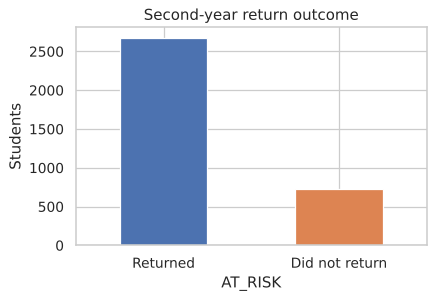

In [3]:
raw['AT_RISK'] = 1 - raw['RETURNED_2ND_YR']
counts = raw['AT_RISK'].value_counts().rename({0: 'Returned', 1: 'Did not return'})
print(counts)
print(f"\nAt-risk rate: {raw['AT_RISK'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts.plot(kind='bar', color=['#4C72B0', '#DD8452'], ax=ax, rot=0)
ax.set_title('Second-year return outcome')
ax.set_ylabel('Students')
plt.tight_layout(); plt.show()

### 2.2 Missing values
Many columns are missing by design: course slots 3–6 are empty when a student took fewer core courses, and `STDNT_TEST_ENTRANCE1` is missing for two-thirds of students (most took only one entrance test). Missingness can carry meaning, so it is checked against the outcome before imputing.

In [4]:
missing = raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].to_frame('share_missing').style.format('{:.1%}')

,share_missing
CORE_COURSE_NAME_6_S,97.6%
CORE_COURSE_GRADE_6_S,97.6%
CORE_COURSE_NAME_6_F,96.2%
CORE_COURSE_GRADE_6_F,96.2%
CORE_COURSE_NAME_5_S,86.8%
CORE_COURSE_GRADE_5_S,86.8%
CORE_COURSE_GRADE_5_F,81.0%
CORE_COURSE_NAME_5_F,81.0%
STDNT_TEST_ENTRANCE1,67.5%
CORE_COURSE_GRADE_4_S,60.1%


### 2.3 Missing second-term data is a strong signal
Students with no second-term hours mostly did not return. If those gaps were filled with the average (as in the first version of this project), that signal would be erased. The pipeline keeps it with explicit "missing" indicator features.

In [5]:
no_t2 = raw['SECOND_TERM_ATTEMPT_HRS'].isna() | (raw['SECOND_TERM_ATTEMPT_HRS'] == 0)
summary = raw.groupby(no_t2.rename('No second-term hours'))['AT_RISK'].agg(students='size', at_risk_rate='mean')
summary.style.format({'at_risk_rate': '{:.1%}'})

,students,at_risk_rate
No second-term hours,,
False,3194,17.0%
True,206,86.9%


### 2.4 At-risk rate by key student attributes

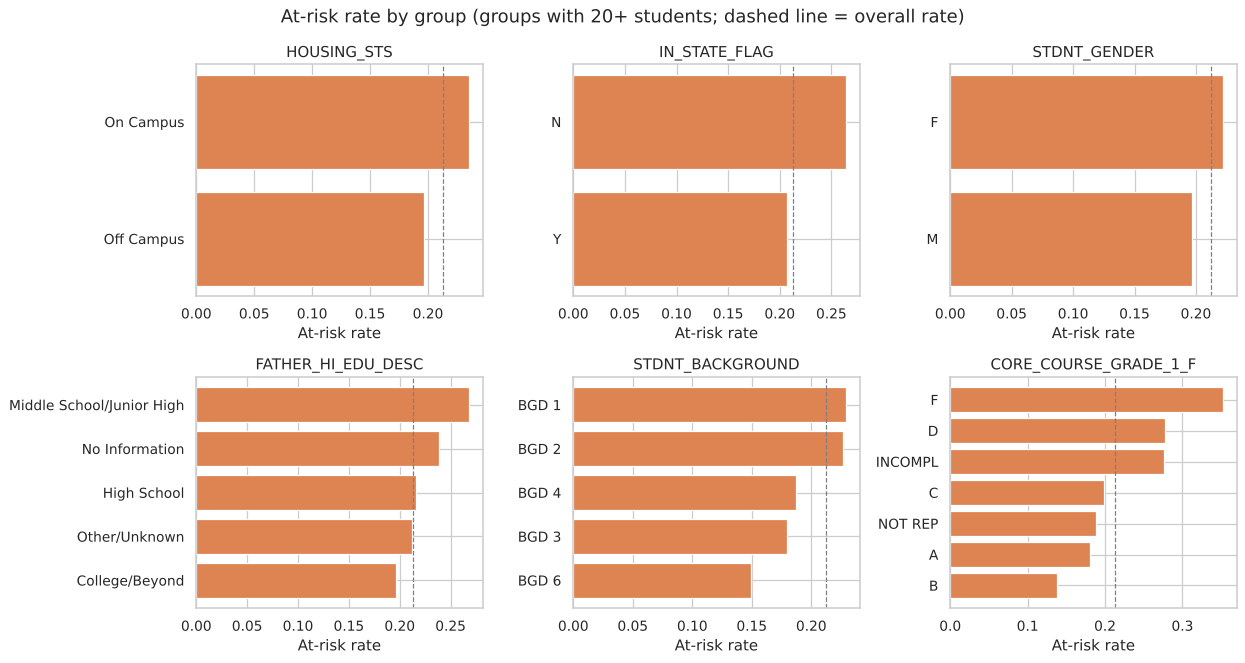

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.ravel(), ['HOUSING_STS', 'IN_STATE_FLAG', 'STDNT_GENDER',
                                  'FATHER_HI_EDU_DESC', 'STDNT_BACKGROUND', 'CORE_COURSE_GRADE_1_F']):
    rates = raw.groupby(col)['AT_RISK'].agg(['mean', 'size'])
    rates = rates[rates['size'] >= 20].sort_values('mean')
    ax.barh(rates.index.astype(str), rates['mean'], color='#DD8452')
    ax.axvline(raw['AT_RISK'].mean(), color='grey', ls='--', lw=1)
    ax.set_title(col); ax.set_xlabel('At-risk rate')
fig.suptitle('At-risk rate by group (groups with 20+ students; dashed line = overall rate)')
plt.tight_layout(); plt.show()

### 2.5 Academic performance vs. outcome
First-term completion (hours earned ÷ hours attempted) and high-school GPA both separate the two groups clearly.

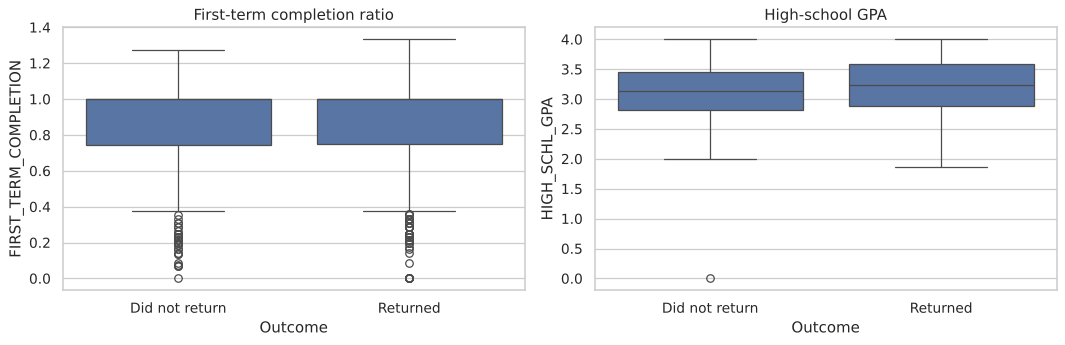

In [7]:
tmp = raw.assign(FIRST_TERM_COMPLETION=raw['FIRST_TERM_EARNED_HRS'] / raw['FIRST_TERM_ATTEMPT_HRS'],
                 Outcome=raw['AT_RISK'].map({0: 'Returned', 1: 'Did not return'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=tmp, x='Outcome', y='FIRST_TERM_COMPLETION', ax=axes[0])
sns.boxplot(data=tmp, x='Outcome', y='HIGH_SCHL_GPA', ax=axes[1])
axes[0].set_title('First-term completion ratio'); axes[1].set_title('High-school GPA')
plt.tight_layout(); plt.show()

## 3) Feature engineering

Every step here works **one row at a time** (no averages, modes or scalers learned from the data), so it is safe to apply before the train/test split. Anything learned from data happens later inside the pipeline.

| Step | Why |
|---|---|
| Map letter grades to points (A=4 … F=0); keep INCOMPL / NOT REP as separate counts | `LabelEncoder` sorted grades alphabetically and mixed in non-grades, which has no meaning |
| Summarise all six course slots per term: core GPA, number of courses, number of F, number of incomplete/not-reported | Uses all course data instead of only slots 1–2, without the sparse columns |
| Completion ratio = earned ÷ attempted hours per term, plus a `NO_SECOND_TERM` flag | Keeps the strongest signal in the data visible to every model |
| `ENTRY_COHORT` = first-term year | Calendar year from `200708` style codes; `SECOND_TERM` is always next year, so it is dropped |
| Drop ID, high-school name, course names, duplicated code columns | Identifiers or near-unique values that don't generalise |

In [8]:
GRADE_POINTS = {'A': 4, 'B': 3, 'C': 2, 'D': 1, 'F': 0}

def term_summary(df, suffix):
    grades = df[[f'CORE_COURSE_GRADE_{i}_{suffix}' for i in range(1, 7)]]
    points = grades.apply(lambda s: s.map(GRADE_POINTS))
    return pd.DataFrame({
        f'CORE_GPA_{suffix}': points.mean(axis=1),
        f'N_CORE_COURSES_{suffix}': grades.notna().sum(axis=1),
        f'N_F_GRADES_{suffix}': (grades == 'F').sum(axis=1),
        f'N_INCOMPLETE_{suffix}': grades.isin(['INCOMPL', 'NOT REP', 'Unknown']).sum(axis=1),
    })

def build_features(df):
    out = pd.DataFrame(index=df.index)
    # Student profile
    for c in ['STDNT_AGE', 'STDNT_GENDER', 'STDNT_BACKGROUND', 'IN_STATE_FLAG', 'INTERNATIONAL_STS',
              'STDNT_MAJOR', 'HOUSING_STS', 'FATHER_HI_EDU_DESC', 'MOTHER_HI_EDU_DESC',
              'DISTANCE_FROM_HOME', 'HIGH_SCHL_GPA', 'STDNT_TEST_ENTRANCE_COMB']:
        out[c] = df[c]
    out['HAS_MINOR'] = (df['STDNT_MINOR'] != 'N').astype(int)
    out['ENTRY_COHORT'] = df['FIRST_TERM'] // 100
    # Finances
    for c in ['GROSS_FIN_NEED', 'COST_OF_ATTEND', 'EST_FAM_CONTRIBUTION', 'UNMET_NEED']:
        out[c] = df[c]
    # First and second term performance
    out['FIRST_TERM_ATTEMPT_HRS'] = df['FIRST_TERM_ATTEMPT_HRS']
    out['FIRST_TERM_COMPLETION'] = df['FIRST_TERM_EARNED_HRS'] / df['FIRST_TERM_ATTEMPT_HRS'].replace(0, np.nan)
    out['SECOND_TERM_ATTEMPT_HRS'] = df['SECOND_TERM_ATTEMPT_HRS'].fillna(0)
    out['SECOND_TERM_COMPLETION'] = df['SECOND_TERM_EARNED_HRS'] / df['SECOND_TERM_ATTEMPT_HRS'].replace(0, np.nan)
    out['NO_SECOND_TERM'] = (out['SECOND_TERM_ATTEMPT_HRS'] == 0).astype(int)
    out = out.join(term_summary(df, 'F')).join(term_summary(df, 'S'))
    return out

X_all = build_features(raw)
y_all = raw['AT_RISK']
print('Feature matrix:', X_all.shape)
X_all.head()

Feature matrix: (3400, 31)


,STDNT_AGE,STDNT_GENDER,STDNT_BACKGROUND,IN_STATE_FLAG,INTERNATIONAL_STS,STDNT_MAJOR,HOUSING_STS,FATHER_HI_EDU_DESC,MOTHER_HI_EDU_DESC,DISTANCE_FROM_HOME,HIGH_SCHL_GPA,STDNT_TEST_ENTRANCE_COMB,HAS_MINOR,ENTRY_COHORT,GROSS_FIN_NEED,COST_OF_ATTEND,EST_FAM_CONTRIBUTION,UNMET_NEED,FIRST_TERM_ATTEMPT_HRS,FIRST_TERM_COMPLETION,SECOND_TERM_ATTEMPT_HRS,SECOND_TERM_COMPLETION,NO_SECOND_TERM,CORE_GPA_F,N_CORE_COURSES_F,N_F_GRADES_F,N_INCOMPLETE_F,CORE_GPA_S,N_CORE_COURSES_S,N_F_GRADES_S,N_INCOMPLETE_S
0,18,F,BGD 1,Y,N,Undeclared,On Campus,No Information,No Information,150.0,4.00,1150.0,0,2007,0,0,0,0.0,16,1.0,14.0,1.0,0,4.0,4,0,0,4.0,4,0,0
1,19,F,BGD 1,N,N,Undeclared,Off Campus,College/Beyond,College/Beyond,69.0,2.89,1190.0,0,2008,570000,1355760,785760,459300.0,18,1.0,18.0,1.0,0,4.0,6,0,0,4.0,2,0,0
2,18,M,BGD 1,Y,N,Mathematics,On Campus,High School,Other/Unknown,150.0,3.39,1030.0,0,2010,0,0,0,0.0,15,1.0,14.0,1.0,0,4.0,5,0,0,4.0,3,0,0
3,18,M,BGD 1,Y,N,Undeclared,On Campus,College/Beyond,College/Beyond,150.0,2.93,1220.0,0,2007,0,0,0,0.0,13,1.0,14.0,1.0,0,4.0,2,0,0,4.0,4,0,0
4,18,F,BGD 1,Y,N,Art,Off Campus,College/Beyond,High School,69.0,3.86,1190.0,0,2008,835920,1355760,519840,278340.0,12,1.0,12.0,1.0,0,4.0,4,0,0,4.0,4,0,0


In [9]:
CATEGORICAL = ['STDNT_GENDER', 'STDNT_BACKGROUND', 'IN_STATE_FLAG', 'INTERNATIONAL_STS', 'STDNT_MAJOR',
               'HOUSING_STS', 'FATHER_HI_EDU_DESC', 'MOTHER_HI_EDU_DESC']
NUMERIC = [c for c in X_all.columns if c not in CATEGORICAL]
print(f'{len(NUMERIC)} numeric features, {len(CATEGORICAL)} categorical features')

23 numeric features, 8 categorical features


## 4) Train/test split

A stratified 80/20 split keeps the at-risk share the same in both sets. The test set is **not touched** until Section 7: all imputation, scaling, encoding, tuning and threshold selection use the training set only.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
print('Train:', X_train.shape, f'at-risk rate {y_train.mean():.1%}')
print('Test: ', X_test.shape, f'at-risk rate {y_test.mean():.1%}')

Train: (2720, 31) at-risk rate 21.2%
Test:  (680, 31) at-risk rate 21.3%


## 5) Leak-free preprocessing pipeline

All learned preprocessing sits in a scikit-learn `Pipeline`, so in cross-validation it is re-fitted inside every fold and never sees the validation rows.

- **Numeric:** median imputation **with missing-value indicator columns**, then standardisation.
- **Categorical:** one-hot encoding (rare categories under 20 students are grouped as "infrequent"). This replaces `LabelEncoder`, which gave categories like major a fake numeric order.
- **Class imbalance:** handled with `class_weight='balanced'` inside each model rather than SMOTE before cross-validation, which had let synthetic copies of validation rows into training folds and inflated CV scores (0.93 CV vs 0.82 test for Extra Trees in the earlier version).

In [11]:
def make_preprocessor():
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                        ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                     min_frequency=20, sparse_output=False))])
    return ColumnTransformer([('num', numeric, NUMERIC), ('cat', categorical, CATEGORICAL)])

def make_pipeline(model):
    return Pipeline([('prep', make_preprocessor()), ('model', model)])

## 6) Model training and tuning

Each candidate is tuned with 5-fold stratified cross-validation on the training set, scored by **ROC-AUC** (how well the model ranks at-risk students above others, independent of any cutoff). A "predict the majority" dummy model is included as the floor every model must beat.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    'Baseline (majority class)': (DummyClassifier(strategy='prior'), {}),
    'Logistic Regression': (LogisticRegression(class_weight='balanced', max_iter=2000),
                            {'model__C': [0.01, 0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(), {'model__n_neighbors': [15, 31, 51], 'model__weights': ['distance']}),
    'SVM (RBF)': (SVC(class_weight='balanced', probability=True, random_state=RANDOM_STATE),
                  {'model__C': [0.3, 1, 3]}),
    'Decision Tree': (DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                      {'model__max_depth': [3, 5, 8], 'model__min_samples_leaf': [10, 30]}),
    'Random Forest': (RandomForestClassifier(class_weight='balanced_subsample', n_estimators=400,
                                             random_state=RANDOM_STATE, n_jobs=-1),
                      {'model__max_depth': [6, 12, None], 'model__min_samples_leaf': [2, 5]}),
    'Extra Trees': (ExtraTreesClassifier(class_weight='balanced_subsample', n_estimators=400,
                                         random_state=RANDOM_STATE, n_jobs=-1),
                    {'model__max_depth': [8, 16, None], 'model__min_samples_leaf': [2, 5]}),
    'Gradient Boosting (HistGB)': (HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
                                   {'model__learning_rate': [0.03, 0.1], 'model__max_depth': [3, 6],
                                    'model__max_iter': [200]}),
}

fitted, cv_rows = {}, []
for name, (model, grid) in candidates.items():
    search = GridSearchCV(make_pipeline(model), grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    best = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    cv_rows.append({'Model': name, 'CV ROC-AUC': search.best_score_,
                    'CV std': search.cv_results_['std_test_score'][search.best_index_], 'Best params': best})

cv_table = pd.DataFrame(cv_rows).sort_values('CV ROC-AUC', ascending=False).reset_index(drop=True)
cv_table.style.format({'CV ROC-AUC': '{:.3f}', 'CV std': '{:.3f}'})

,Model,CV ROC-AUC,CV std,Best params
0,Gradient Boosting (HistGB),0.742,0.012,"{'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 200}"
1,Logistic Regression,0.731,0.017,{'C': 0.1}
2,SVM (RBF),0.729,0.016,{'C': 0.3}
3,Random Forest,0.728,0.007,"{'max_depth': 12, 'min_samples_leaf': 5}"
4,Extra Trees,0.724,0.018,"{'max_depth': 8, 'min_samples_leaf': 5}"
5,Decision Tree,0.703,0.033,"{'max_depth': 5, 'min_samples_leaf': 30}"
6,KNN,0.697,0.013,"{'n_neighbors': 51, 'weights': 'distance'}"
7,Baseline (majority class),0.500,0.000,{}


### 6.1 Optional: SMOTE + XGBoost done correctly
The original project used SMOTE and XGBoost. If both libraries are installed (they are in Google Colab: `pip install imbalanced-learn xgboost`), this cell runs them with SMOTE **inside** an `imblearn` pipeline, so oversampling happens only on each training fold. Otherwise it is skipped and the rest of the notebook is unaffected.

In [13]:
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    from xgboost import XGBClassifier
    smote_xgb = ImbPipeline([('prep', make_preprocessor()),
                             ('smote', SMOTE(random_state=RANDOM_STATE)),
                             ('model', XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE))])
    search = GridSearchCV(smote_xgb, {'model__n_estimators': [200], 'model__max_depth': [3, 5],
                                      'model__learning_rate': [0.05, 0.1]},
                          cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
    fitted['SMOTE + XGBoost'] = search.best_estimator_
    print(f'SMOTE + XGBoost CV ROC-AUC: {search.best_score_:.3f}  {search.best_params_}')
except ImportError as e:
    print(f'Skipped (optional library not installed: {e.name}).')

Skipped (optional library not installed: imblearn).


## 7) Test-set evaluation

Metrics, with **at-risk students as the positive class**:
- **ROC-AUC:** chance the model ranks a random at-risk student above a random returning one (0.5 = coin flip).
- **PR-AUC:** average precision across cutoffs; the baseline equals the at-risk rate (~0.21).
- **Recall:** share of at-risk students the model flags. **Precision:** share of flagged students who are actually at risk.

Recall/precision here use the default 0.5 probability cutoff; Section 8 chooses a better cutoff.

In [14]:
def evaluate(model, X, y, threshold=0.5):
    p = model.predict_proba(X)[:, 1]
    pred = (p >= threshold).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'Recall (at-risk)': recall_score(y, pred, zero_division=0),
            'Precision (at-risk)': precision_score(y, pred, zero_division=0),
            'F1 (at-risk)': f1_score(y, pred, zero_division=0), 'Accuracy': accuracy_score(y, pred)}

test_table = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in fitted.items()}).T
test_table = test_table.sort_values('ROC-AUC', ascending=False)
test_table.style.format('{:.3f}').background_gradient(subset=['ROC-AUC', 'PR-AUC'], cmap='Greens')

,ROC-AUC,PR-AUC,Recall (at-risk),Precision (at-risk),F1 (at-risk),Accuracy
Random Forest,0.771,0.586,0.455,0.653,0.537,0.832
Logistic Regression,0.771,0.583,0.607,0.463,0.525,0.766
Gradient Boosting (HistGB),0.758,0.577,0.579,0.519,0.547,0.796
Extra Trees,0.758,0.579,0.490,0.592,0.536,0.819
Decision Tree,0.742,0.511,0.510,0.481,0.495,0.778
SVM (RBF),0.738,0.482,0.372,0.635,0.470,0.821
KNN,0.702,0.551,0.290,0.875,0.435,0.840
Baseline (majority class),0.500,0.213,0.000,0.000,0.000,0.787


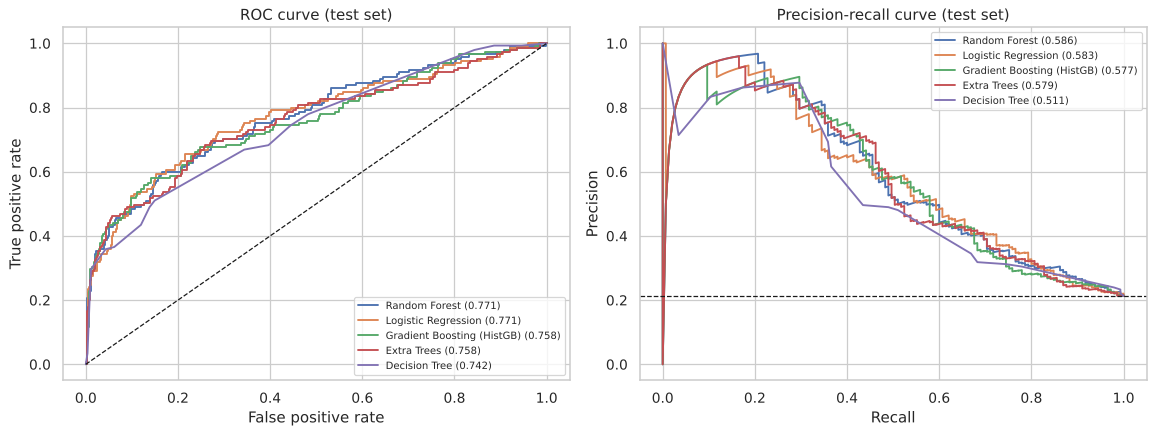

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in test_table.index[:5]:
    p = fitted[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p); prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{name} ({roc_auc_score(y_test, p):.3f})')
    axes[1].plot(rec, prec, label=f'{name} ({average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve (test set)')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1); axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve (test set)')
for ax in axes: ax.legend(fontsize=8, loc='best')
plt.tight_layout(); plt.show()

## 8) Decision threshold and risk tiers

### 8.1 Choosing the cutoff
The model outputs a risk probability; the cutoff for "flag this student" is a business decision. It is chosen here using **out-of-fold predictions on the training set** (never the test set) as the cutoff that maximises F1 for at-risk students. Advisors with more capacity could use a lower cutoff to catch more students.

The model used from here on is the one with the best **cross-validated** ROC-AUC (selected on training data, not on the test results).

In [16]:
best_name = cv_table.loc[cv_table['Model'] != 'Baseline (majority class)', 'Model'].iloc[0]
best_model = fitted[best_name]
print('Selected model:', best_name)

oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
THRESHOLD = float(thr[np.argmax(f1)])
print(f'Chosen cutoff (max out-of-fold F1): {THRESHOLD:.3f}')

comparison = pd.DataFrame({'Default cutoff 0.50': evaluate(best_model, X_test, y_test, 0.5),
                           f'Tuned cutoff {THRESHOLD:.2f}': evaluate(best_model, X_test, y_test, THRESHOLD)}).T
comparison.style.format('{:.3f}')

Selected model: Gradient Boosting (HistGB)
Chosen cutoff (max out-of-fold F1): 0.527


,ROC-AUC,PR-AUC,Recall (at-risk),Precision (at-risk),F1 (at-risk),Accuracy
Default cutoff 0.50,0.758,0.577,0.579,0.519,0.547,0.796
Tuned cutoff 0.53,0.758,0.577,0.538,0.553,0.545,0.809


              precision    recall  f1-score   support

    Returned       0.88      0.88      0.88       535
     At risk       0.55      0.54      0.55       145

    accuracy                           0.81       680
   macro avg       0.71      0.71      0.71       680
weighted avg       0.81      0.81      0.81       680



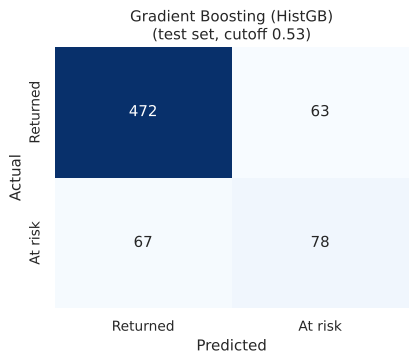

In [17]:
p_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_test, target_names=['Returned', 'At risk']))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Returned', 'At risk'], yticklabels=['Returned', 'At risk'])
ax.set(xlabel='Predicted', ylabel='Actual', title=f'{best_name}\n(test set, cutoff {THRESHOLD:.2f})')
plt.tight_layout(); plt.show()

### 8.2 Risk tiers
For outreach planning it is often more useful to rank students than to give a yes/no. The table splits test students into five equal groups by predicted risk and shows how many in each group actually did not return.

In [18]:
tiers = pd.DataFrame({'risk': p_test, 'actual': y_test.values})
tiers['Risk tier'] = pd.qcut(tiers['risk'].rank(method='first'), 5,
                             labels=['1 Lowest', '2 Low', '3 Medium', '4 High', '5 Highest'])
tier_table = tiers.groupby('Risk tier', observed=True).agg(students=('actual', 'size'),
                                                          did_not_return=('actual', 'sum'),
                                                          actual_rate=('actual', 'mean'))
tier_table['share_of_all_leavers'] = tier_table['did_not_return'] / tier_table['did_not_return'].sum()
tier_table.iloc[::-1].style.format({'actual_rate': '{:.1%}', 'share_of_all_leavers': '{:.1%}'})

,students,did_not_return,actual_rate,share_of_all_leavers
Risk tier,,,,
5 Highest,136,77,56.6%,53.1%
4 High,136,22,16.2%,15.2%
3 Medium,136,15,11.0%,10.3%
2 Low,136,21,15.4%,14.5%
1 Lowest,136,10,7.4%,6.9%


## 9) Model explainability

**Permutation importance** on the test set: shuffle one original feature at a time and measure how much ROC-AUC drops. Because it works on the raw input columns, the results are in business terms and don't depend on how a feature was encoded.

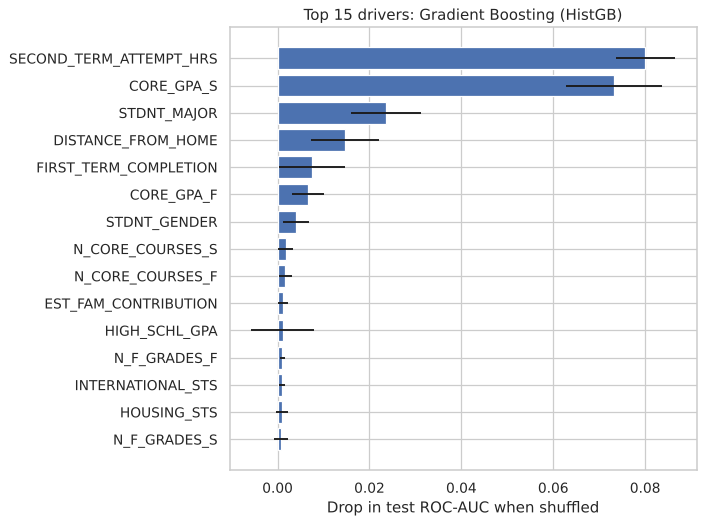

,importance
SECOND_TERM_ATTEMPT_HRS,0.0801
CORE_GPA_S,0.0732
STDNT_MAJOR,0.0236
DISTANCE_FROM_HOME,0.0147
FIRST_TERM_COMPLETION,0.0075
CORE_GPA_F,0.0066
STDNT_GENDER,0.0039
N_CORE_COURSES_S,0.0017
N_CORE_COURSES_F,0.0017
EST_FAM_CONTRIBUTION,0.0013


In [19]:
perm = permutation_importance(best_model, X_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, xerr=pd.Series(perm.importances_std, index=X_test.columns)[top.index], color='#4C72B0')
ax.set(xlabel='Drop in test ROC-AUC when shuffled', title=f'Top 15 drivers: {best_name}')
plt.tight_layout(); plt.show()
imp.head(10).round(4).to_frame('importance')

**Direction of effects.** Logistic regression coefficients (standardised features) show whether each driver raises or lowers risk. Positive = higher risk of not returning.

In [20]:
lr = fitted['Logistic Regression']
names = lr.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr.named_steps['model'].coef_[0], index=names)
coef.index = coef.index.str.replace('num__', '').str.replace('cat__', '')
coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).round(3).to_frame('LR coefficient')

,LR coefficient
STDNT_MAJOR_Theatre Arts,-0.540
STDNT_MAJOR_Joint Enrollment - Accel,-0.502
STDNT_MAJOR_Music Education,-0.429
CORE_GPA_S,-0.424
NO_SECOND_TERM,0.407
STDNT_BACKGROUND_BGD 1,0.397
STDNT_MAJOR_Pre-Nursing,0.384
STDNT_MAJOR_Psychology,0.340
STDNT_MAJOR_Criminal Justice,0.321
STDNT_MAJOR_General Business,-0.301


## 10) Robustness checks

### 10.1 Does it work on a new cohort?
A random split mixes all years together. A stricter test trains on the 2005–2009 entry cohorts and tests on the **2010 cohort**, which the model has never seen, as it would be used in practice.

In [21]:
is_2010 = X_all['ENTRY_COHORT'] == 2010
temporal = make_pipeline(best_model.named_steps['model'].__class__(**best_model.named_steps['model'].get_params()))
temporal.fit(X_all[~is_2010], y_all[~is_2010])
temporal_result = evaluate(temporal, X_all[is_2010], y_all[is_2010], THRESHOLD)
pd.Series(temporal_result, name=f'{best_name}: train 2005–09, test 2010 (n={is_2010.sum()})').round(3).to_frame()

,"Gradient Boosting (HistGB): train 2005–09, test 2010 (n=632)"
ROC-AUC,0.758
PR-AUC,0.596
Recall (at-risk),0.521
Precision (at-risk),0.593
F1 (at-risk),0.555
Accuracy,0.815


### 10.2 Early-warning version (end of first term)
The main model uses second-term data, so it scores students only at the **end of their first year**. An earlier, actionable version uses only what is known after the **first term** (profile, finances, first-term grades). It trades some accuracy for one extra semester of lead time.

In [22]:
SECOND_TERM_COLS = [c for c in X_all.columns if c.endswith('_S') or c.startswith('SECOND_TERM') or c == 'NO_SECOND_TERM']
early_numeric = [c for c in NUMERIC if c not in SECOND_TERM_COLS]
early_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())]), early_numeric),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False))]), CATEGORICAL)])
early_model = Pipeline([('prep', early_prep),
                        ('model', best_model.named_steps['model'].__class__(**best_model.named_steps['model'].get_params()))])
early_model.fit(X_train.drop(columns=SECOND_TERM_COLS), y_train)
early_oof = cross_val_predict(early_model, X_train.drop(columns=SECOND_TERM_COLS), y_train, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
pe, re_, te = precision_recall_curve(y_train, early_oof)
EARLY_THRESHOLD = float(te[np.argmax(2 * pe[:-1] * re_[:-1] / (pe[:-1] + re_[:-1] + 1e-12))])

pd.DataFrame({'End of year 1 (main model)': evaluate(best_model, X_test, y_test, THRESHOLD),
              'End of term 1 (early warning)': evaluate(early_model, X_test.drop(columns=SECOND_TERM_COLS), y_test, EARLY_THRESHOLD)}).T.style.format('{:.3f}')

,ROC-AUC,PR-AUC,Recall (at-risk),Precision (at-risk),F1 (at-risk),Accuracy
End of year 1 (main model),0.758,0.577,0.538,0.553,0.545,0.809
End of term 1 (early warning),0.669,0.373,0.731,0.275,0.399,0.531


## 11) Conclusions, limitations and next steps

### Key findings
1. **The best models rank students well but not perfectly.** On the held-out test set the top models reach **ROC-AUC ≈ 0.76–0.77** and **PR-AUC ≈ 0.58** (a random guess would get 0.50 and 0.21). Cross-validated AUC was 0.70–0.74 for every model, and the test scores land close to that, so the reported performance is honest. Logistic regression, random forest and gradient boosting perform within about 0.01 AUC of each other.
2. **The selected model (Gradient Boosting, chosen on cross-validation) finds about half of all leavers.** At the tuned cutoff it flags 54% of students who did not return, and 55% of the students it flags really are at risk (F1 0.55). The first version of this project reported 85% accuracy, but on its own test set it caught only about a third of leavers. Accuracy looked high because 79% of students return anyway.
3. **Risk tiers make the model usable.** The **highest-risk 20%** of test students contains **53% of all leavers**, with an actual non-return rate of 57%, almost three times the 21% average. Concentrating outreach on that tier is the clearest operational win.
4. **What drives risk.** By far the strongest signals are second-term engagement and performance: **second-term hours attempted** (students who don't enrol or enrol lightly) and **second-term core GPA**. Next come major, distance from home, and first-term completion and GPA. Financial variables and entrance-test scores add little once academic performance is known.
5. **It holds up on a new cohort.** Trained on 2005–2009 and tested on the unseen 2010 cohort, the model scores ROC-AUC 0.76, the same as the random split. That suggests it would transfer to the next intake.

### Limitations
- **Timing.** The main model needs second-term data, so it scores students only at the end of year 1, close to the re-enrolment decision. The early-warning version (first-term data only) gives one more semester of lead time but is much weaker (ROC-AUC 0.67; at its cutoff it catches 73% of leavers with only 27% precision).
- **Moderate ceiling.** Around half of leavers look like returners on paper. Reasons such as family, health, transfer or work are not in the data.
- **Data age and size.** 3,400 students from 2005–2010 cohorts at one institution. Patterns may have shifted since then and should be re-validated on recent data.
- **Fairness.** Gender, background and parental education are inputs. Before deployment the model's error rates should be checked by group, and the institution should decide whether any of these attributes should be used.
- **Correlation, not cause.** Feature importance shows what predicts leaving, not what would prevent it.

### Recommendations and next steps
1. **Pilot a risk-tier outreach programme**: advisors contact the top tier at the end of each first-year spring term, and the institution measures the change in return rate against a comparison group.
2. **Run the early-warning model after term 1** as a softer, wider screen (e.g. tutoring or check-in invitations), since a false alarm costs little at that stage.
3. **Add earlier and richer signals**: mid-term grades, LMS activity, attendance, advising contacts and financial-aid holds would likely improve both models most.
4. **Retrain yearly** on the newest cohorts, monitor performance and fairness by group, and recalibrate the cutoff to match advising capacity.